# Практичне заняття № 9 — Нейронні мережі

**Завдання.** Створити нейронну мережу, яка може розпізнавати рукописні цифри,
зображені на зображеннях. Використати набір даних MNIST, навчити мережу та
оцінити її ефективність у розпізнаванні нових зображень.

**Датасет: MNIST** — 10 000 зображень 28×28, 784 ознаки-пікселі, 10 збалансованих
класів. Той самий набір і той самий поділ, що в практичному занятті № 7, де вже
виміряно сім інших алгоритмів — тож результат мережі порівнюється безпосередньо.

## Теорія

Штучний нейрон підсумовує зважені входи й пропускає результат через функцію
активації: $y = f(\sum_i w_i x_i + b)$. Мережа без прихованих шарів, з однією
сигмоїдною активацією на виході — це в точності логістична регресія з
практичного заняття № 1; усе інше є її узагальненням.

Навчання виконується **зворотним поширенням помилки**: похибка на виході
пошириюється назад крізь шари, і ваги коригуються градієнтним спуском.

## Правила з методичних вказівок, які буде перевірено

Методичка наводить два кількісні орієнтири для вибору архітектури:

1. **Теорема Колмогорова**: будь-яку функцію $n$ змінних можна подати
   суперпозицією $2n+1$ одновимірних, звідки «немає сенсу обирати кількість
   прихованих нейронів більшу за подвоєну кількість вхідних». Для MNIST це
   $2 \cdot 784 + 1 = 1569$ нейронів.
2. **Достатність даних**: $w < n / e$, де $w$ — кількість ваг, $n$ — кількість
   навчальних прикладів, $e$ — прийнятна похибка.

Обидва правила буде перевірено емпірично, а не просто процитовано.

In [1]:
# --- Підготовка даних -------------------------------------------------------
# Ноутбук має запускатися і локально, і в Colab. Якщо потрібного файлу немає,
# він завантажується з Kaggle. Форму таблиці перевіряємо одразу: Kaggle може
# оновити версію набору, і краще впасти тут, ніж мовчки отримати інші числа,
# ніж у звіті.
import importlib.util
import shutil
import subprocess
import sys
from pathlib import Path


def _in_colab():
    if "google.colab" in sys.modules:
        return True
    try:
        return importlib.util.find_spec("google.colab") is not None
    except (ImportError, ValueError):
        # find_spec імпортує батьківський пакет; без нього — це не Colab
        return False


IN_COLAB = _in_colab()
DATA = Path("data"); DATA.mkdir(exist_ok=True)
ASSETS = Path("assets"); ASSETS.mkdir(exist_ok=True)

# (локальна назва, slug на Kaggle, файл у наборі, колонок, рядків, кодування)
DATASETS = [
    ('mnist.csv', 'wasiqaliyasir/digital-mnist-dataset',
     'mnist.csv', 785, 10000, 'utf-8')
]


def _ensure_packages():
    """У Colab більшість пакетів уже є; доставляємо лише те, чого бракує."""
    missing = [p for p in ("pandas", "sklearn", "matplotlib", "seaborn", "kagglehub")
               if importlib.util.find_spec(p) is None]
    if missing:
        names = {"sklearn": "scikit-learn"}
        pkgs = [names.get(m, m) for m in missing]
        print("встановлюю:", ", ".join(pkgs))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)


def _check(path, ncols, nrows, encoding):
    # Перевіряємо і колонки, і рядки: нова версія набору може зберегти структуру,
    # але змінити обсяг — і числа у звіті тихо перестануть збігатися.
    import pandas as pd
    got = pd.read_csv(path, encoding=encoding).shape
    if got != (nrows, ncols):
        raise ValueError(f"{path.name}: очікували {nrows}×{ncols}, отримали {got[0]}×{got[1]}")


def _ensure(local, slug, member, ncols, nrows, encoding):
    dst = DATA / local
    if dst.exists():
        _check(dst, ncols, nrows, encoding)
        print(f"на місці: {dst} ({dst.stat().st_size / 1e6:.1f} МБ)")
        return
    if importlib.util.find_spec("kagglehub"):
        import kagglehub
        print(f"завантажую {slug} …")
        root = Path(kagglehub.dataset_download(slug))
        src = next(iter(root.rglob(member)), None)
        if src is None:   # назву файлу в наборі могли змінити — беремо найбільший CSV
            src = max(root.rglob("*.csv"), key=lambda f: f.stat().st_size)
        shutil.copy(src, dst)
        _check(dst, ncols, nrows, encoding)
        print(f"готово: {dst} ({dst.stat().st_size / 1e6:.1f} МБ)")
        return
    raise FileNotFoundError(
        f"{dst} не знайдено. Візьміть набір за адресою "
        f"https://www.kaggle.com/datasets/{slug} і покладіть файл у {DATA}/ "
        f"під назвою {local}."
    )


if IN_COLAB:
    _ensure_packages()
for _args in DATASETS:
    _ensure(*_args)

на місці: data/mnist.csv (18.3 МБ)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from pathlib import Path

from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
ASSETS = Path("assets"); ASSETS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
np.random.seed(RANDOM_STATE)

## 1. Дані

In [3]:
df = pd.read_csv("data/mnist.csv")
y = df["label"].values
# Нормуємо пікселі до [0,1] — для градієнтного спуску це принципово:
# з діапазоном 0..255 градієнти на початку навчання завеликі
X = df.drop(columns=["label"]).values.astype(np.float32) / 255.0

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)

N_TRAIN, N_FEAT = X_train.shape
print(f"Навчальна: {X_train.shape}, тестова: {X_test.shape}")
print(f"Класи: {dict(pd.Series(y).value_counts().sort_index())}")
print(f"Межа Колмогорова 2n+1 = {2*N_FEAT+1} прихованих нейронів")

Навчальна: (7500, 784), тестова: (2500, 784)
Класи: {0: np.int64(980), 1: np.int64(1135), 2: np.int64(1032), 3: np.int64(1010), 4: np.int64(982), 5: np.int64(892), 6: np.int64(958), 7: np.int64(1028), 8: np.int64(974), 9: np.int64(1009)}
Межа Колмогорова 2n+1 = 1569 прихованих нейронів


## 2. Розмір прихованого шару

Перевіряємо перше правило. Для кожної архітектури рахуємо кількість ваг

$$w = n_{\text{вх}} \cdot h + h + h \cdot n_{\text{вих}} + n_{\text{вих}}$$

і порівнюємо з обома орієнтирами методички.

In [4]:
def n_weights(h_sizes, n_in=N_FEAT, n_out=10):
    sizes = [n_in] + list(h_sizes) + [n_out]
    return sum(sizes[i]*sizes[i+1] + sizes[i+1] for i in range(len(sizes)-1))

hidden_sizes = [10, 25, 50, 100, 200, 400, 800]
arch_rows = []
for h in hidden_sizes:
    t0 = time.time()
    mlp = MLPClassifier(hidden_layer_sizes=(h,), max_iter=100,
                        random_state=RANDOM_STATE).fit(X_train, y_train)
    w = n_weights((h,))
    tr, te = mlp.score(X_train, y_train), mlp.score(X_test, y_test)
    arch_rows.append({
        "Нейронів": h, "Ваг": w,
        "Ваг/приклад": w / N_TRAIN,
        "Навчальна": tr, "Тестова": te, "Розрив": tr - te,
        "Час, с": time.time() - t0,
    })
    print(f"  h={h:4}: ваг={w:7}  навч={tr:.4f}  тест={te:.4f}  розрив={tr-te:.4f}")

arch_df = pd.DataFrame(arch_rows)
arch_df.to_csv("data/architecture.csv", index=False)
arch_df.round(4)

.../site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


  h=  10: ваг=   7960  навч=0.9812  тест=0.9136  розрив=0.0676


.../site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


  h=  25: ваг=  19885  навч=0.9999  тест=0.9324  розрив=0.0675


.../site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


  h=  50: ваг=  39760  навч=1.0000  тест=0.9440  розрив=0.0560


... (2 outputs left out)

  h= 200: ваг= 159010  навч=1.0000  тест=0.9536  розрив=0.0464


  h= 400: ваг= 318010  навч=1.0000  тест=0.9556  розрив=0.0444


  h= 800: ваг= 636010  навч=1.0000  тест=0.9596  розрив=0.0404


,Нейронів,Ваг,Ваг/приклад,Навчальна,Тестова,Розрив,"Час, с"
0,10,7960,1.0613,0.9812,0.9136,0.0676,2.8526
1,25,19885,2.6513,0.9999,0.9324,0.0675,4.8866
2,50,39760,5.3013,1.0000,0.9440,0.0560,28.1190
3,100,79510,10.6013,1.0000,0.9456,0.0544,39.7331
4,200,159010,21.2013,1.0000,0.9536,0.0464,38.5850
5,400,318010,42.4013,1.0000,0.9556,0.0444,51.1230
6,800,636010,84.8013,1.0000,0.9596,0.0404,58.6307


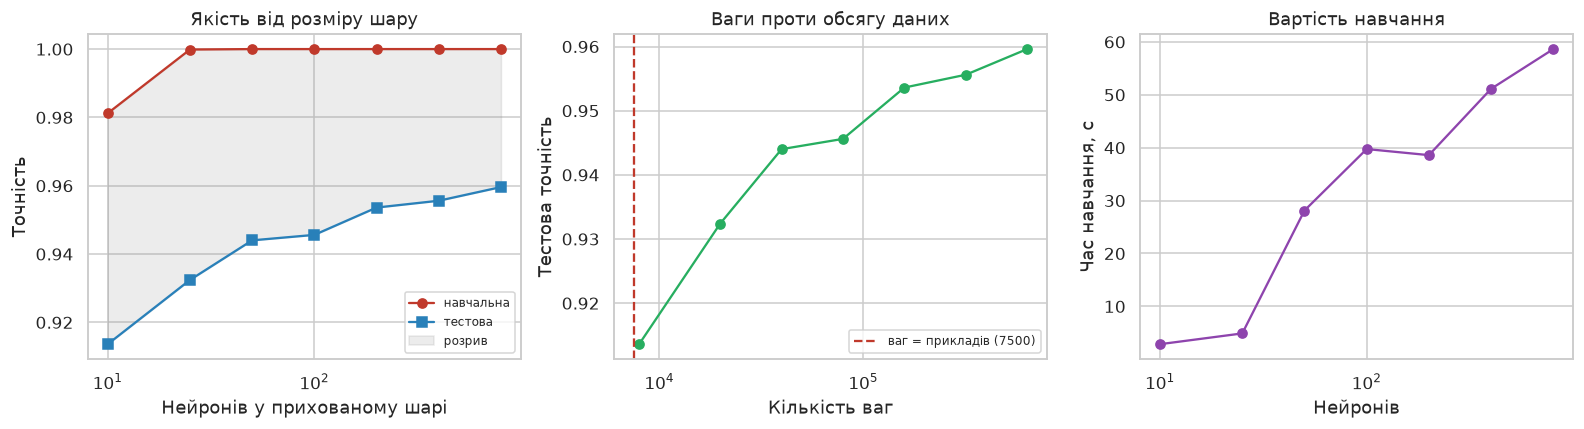

In [5]:
# --- Рисунок 1: розмір шару ---
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4))

axes[0].plot(arch_df["Нейронів"], arch_df["Навчальна"], "o-", color="#c0392b", label="навчальна")
axes[0].plot(arch_df["Нейронів"], arch_df["Тестова"], "s-", color="#2980b9", label="тестова")
axes[0].fill_between(arch_df["Нейронів"], arch_df["Тестова"], arch_df["Навчальна"],
                     alpha=0.15, color="gray", label="розрив")
axes[0].set_xscale("log"); axes[0].set_xlabel("Нейронів у прихованому шарі")
axes[0].set_ylabel("Точність"); axes[0].set_title("Якість від розміру шару")
axes[0].legend(fontsize=8)

axes[1].plot(arch_df["Ваг"], arch_df["Тестова"], "o-", color="#27ae60")
axes[1].axvline(N_TRAIN, color="#c0392b", linestyle="--",
                label=f"ваг = прикладів ({N_TRAIN})")
axes[1].set_xscale("log"); axes[1].set_xlabel("Кількість ваг")
axes[1].set_ylabel("Тестова точність")
axes[1].set_title("Ваги проти обсягу даних"); axes[1].legend(fontsize=8)

axes[2].plot(arch_df["Нейронів"], arch_df["Час, с"], "o-", color="#8e44ad")
axes[2].set_xscale("log"); axes[2].set_xlabel("Нейронів")
axes[2].set_ylabel("Час навчання, с"); axes[2].set_title("Вартість навчання")

plt.tight_layout()
plt.savefig(ASSETS / "01-architecture.png", bbox_inches="tight")
plt.show()

### Перевірка правил методички

Обидва орієнтири зіставляємо з фактичними результатами.

In [6]:
print(f"Правило 1 — межа Колмогорова: не більше {2*N_FEAT+1} нейронів.")
best_h = int(arch_df.loc[arch_df['Тестова'].idxmax(), 'Нейронів'])
print(f"  Найкраща архітектура з випробуваних: {best_h} нейронів —")
print(f"  це {best_h/(2*N_FEAT+1):.1%} від межі, тобто правило не є обмежувальним:")
print("  задовго до нього якість виходить на плато.\n")

print(f"Правило 2 — достатність даних: w < n/e, тобто e < n/w.")
print(f"  n = {N_TRAIN} навчальних прикладів.\n")
print(f"  {'Нейронів':>9} {'Ваг':>8} {'Прогноз e':>11} {'Факт e':>9}  Правило")
for _, r in arch_df.iterrows():
    predicted = N_TRAIN / r["Ваг"]        # e < n/w
    actual = 1 - r["Тестова"]
    ok = "виконано" if actual < predicted else "ПОРУШЕНО"
    print(f"  {int(r['Нейронів']):>9} {int(r['Ваг']):>8} {predicted:>11.3f} {actual:>9.3f}  {ok}")

Правило 1 — межа Колмогорова: не більше 1569 нейронів.
  Найкраща архітектура з випробуваних: 800 нейронів —
  це 51.0% від межі, тобто правило не є обмежувальним:
  задовго до нього якість виходить на плато.

Правило 2 — достатність даних: w < n/e, тобто e < n/w.
  n = 7500 навчальних прикладів.

   Нейронів      Ваг   Прогноз e    Факт e  Правило
         10     7960       0.942     0.086  виконано
         25    19885       0.377     0.068  виконано
         50    39760       0.189     0.056  виконано
        100    79510       0.094     0.054  виконано
        200   159010       0.047     0.046  виконано
        400   318010       0.024     0.044  ПОРУШЕНО
        800   636010       0.012     0.040  ПОРУШЕНО


## 3. Глибина мережі та функція активації

In [7]:
depth_rows = []
for name, arch in [("1 шар (100)", (100,)),
                   ("2 шари (100, 100)", (100, 100)),
                   ("3 шари (100, 100, 100)", (100, 100, 100)),
                   ("Звужувана (300, 100, 30)", (300, 100, 30)),
                   ("Розширювана (30, 100, 300)", (30, 100, 300))]:
    t0 = time.time()
    m = MLPClassifier(hidden_layer_sizes=arch, max_iter=100,
                      random_state=RANDOM_STATE).fit(X_train, y_train)
    depth_rows.append({"Архітектура": name, "Ваг": n_weights(arch),
                       "Навчальна": m.score(X_train, y_train),
                       "Тестова": m.score(X_test, y_test),
                       "Час, с": time.time() - t0})
depth_df = pd.DataFrame(depth_rows).set_index("Архітектура")
depth_df.round(4)

.../site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


,Ваг,Навчальна,Тестова,"Час, с"
Архітектура,,,,
1 шар (100),79510,1.0,0.9456,42.8261
"2 шари (100, 100)",89610,1.0,0.9608,41.3382
"3 шари (100, 100, 100)",99710,1.0,0.9512,27.7326
"Звужувана (300, 100, 30)",268940,1.0,0.9576,36.9698
"Розширювана (30, 100, 300)",59960,1.0,0.9548,39.2720


In [8]:
act_rows = []
for act in ["relu", "tanh", "logistic"]:
    t0 = time.time()
    m = MLPClassifier(hidden_layer_sizes=(200,), activation=act, max_iter=100,
                      random_state=RANDOM_STATE).fit(X_train, y_train)
    act_rows.append({"Активація": act, "Навчальна": m.score(X_train, y_train),
                     "Тестова": m.score(X_test, y_test),
                     "Ітерацій": m.n_iter_, "Час, с": time.time() - t0})
act_df = pd.DataFrame(act_rows).set_index("Активація")
act_df.round(4)

.../site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


,Навчальна,Тестова,Ітерацій,"Час, с"
Активація,,,,
relu,1.0,0.9536,70,28.7467
tanh,1.0,0.9472,80,30.8309
logistic,1.0,0.9488,100,43.3446


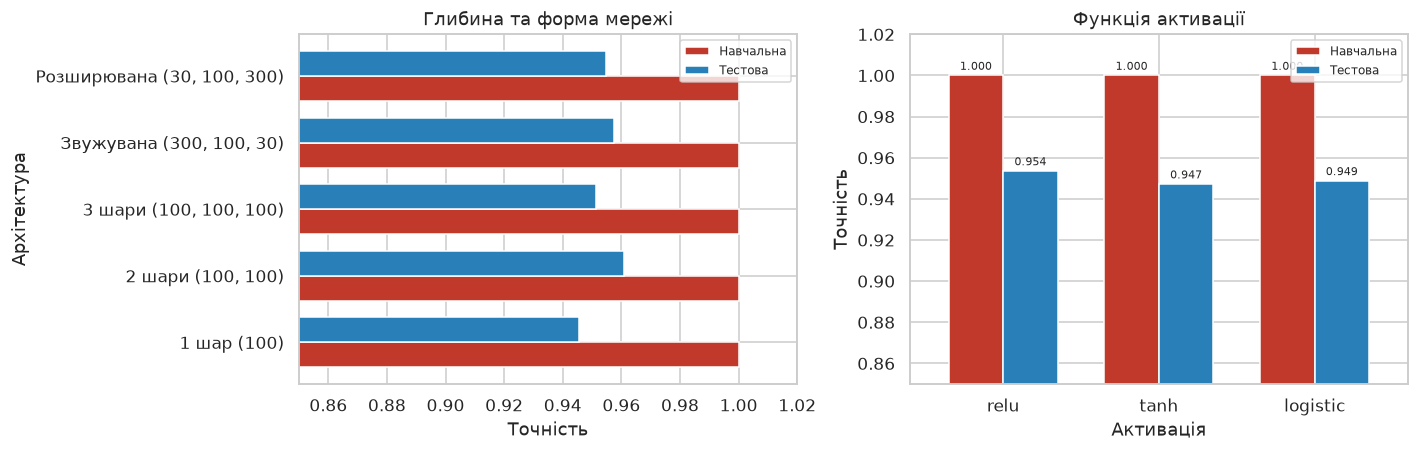

In [9]:
# --- Рисунок 2: глибина та активація ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
depth_df[["Навчальна", "Тестова"]].plot.barh(ax=axes[0], color=["#c0392b", "#2980b9"], width=0.75)
axes[0].set_xlim(0.85, 1.02); axes[0].set_xlabel("Точність")
axes[0].set_title("Глибина та форма мережі"); axes[0].legend(fontsize=8)

act_df[["Навчальна", "Тестова"]].plot.bar(ax=axes[1], rot=0, color=["#c0392b", "#2980b9"], width=0.7)
axes[1].set_ylim(0.85, 1.02); axes[1].set_ylabel("Точність")
axes[1].set_title("Функція активації"); axes[1].legend(fontsize=8)
for cont in axes[1].containers:
    axes[1].bar_label(cont, fmt="%.3f", fontsize=7, padding=2)
plt.tight_layout()
plt.savefig(ASSETS / "02-depth-activation.png", bbox_inches="tight")
plt.show()

## 4. Регуляризація

Усі архітектури досягають 100 % на навчальній вибірці — мережа запам'ятовує дані
повністю. Параметр `alpha` задає штраф на величину ваг (L2-регуляризацію) і
обмежує це запам'ятовування.

In [10]:
alphas = [1e-6, 1e-4, 1e-2, 1e-1, 1.0, 10.0]
reg_rows = []
for a in alphas:
    m = MLPClassifier(hidden_layer_sizes=(200,), alpha=a, max_iter=100,
                      random_state=RANDOM_STATE).fit(X_train, y_train)
    reg_rows.append({"alpha": a, "Навчальна": m.score(X_train, y_train),
                     "Тестова": m.score(X_test, y_test),
                     "Розрив": m.score(X_train, y_train) - m.score(X_test, y_test)})
reg_df = pd.DataFrame(reg_rows)
reg_df.to_csv("data/regularization.csv", index=False)
reg_df.round(4)

,alpha,Навчальна,Тестова,Розрив
0,0.0000,1.0000,0.9556,0.0444
1,0.0001,1.0000,0.9536,0.0464
2,0.0100,1.0000,0.9568,0.0432
3,0.1000,1.0000,0.9580,0.0420
4,1.0000,0.9787,0.9448,0.0339
5,10.0000,0.8936,0.8804,0.0132


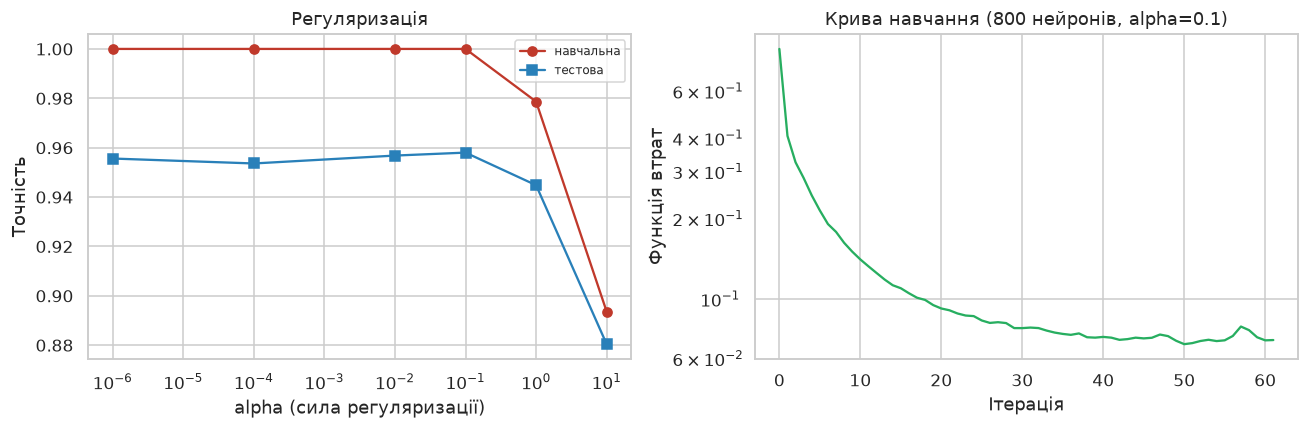

Підсумкова мережа: (800,), alpha=0.1
  навчальна 0.9999, тестова 0.9652


In [11]:
# --- Рисунок 3: регуляризація та крива навчання ---
best_arch = (int(arch_df.loc[arch_df["Тестова"].idxmax(), "Нейронів"]),)
best_alpha = float(reg_df.loc[reg_df["Тестова"].idxmax(), "alpha"])

final = MLPClassifier(hidden_layer_sizes=best_arch, alpha=best_alpha,
                      max_iter=200, random_state=RANDOM_STATE).fit(X_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(reg_df["alpha"], reg_df["Навчальна"], "o-", color="#c0392b", label="навчальна")
axes[0].plot(reg_df["alpha"], reg_df["Тестова"], "s-", color="#2980b9", label="тестова")
axes[0].set_xscale("log"); axes[0].set_xlabel("alpha (сила регуляризації)")
axes[0].set_ylabel("Точність"); axes[0].set_title("Регуляризація"); axes[0].legend(fontsize=8)

axes[1].plot(final.loss_curve_, color="#27ae60")
axes[1].set_xlabel("Ітерація"); axes[1].set_ylabel("Функція втрат")
axes[1].set_title(f"Крива навчання ({best_arch[0]} нейронів, alpha={best_alpha})")
axes[1].set_yscale("log")
plt.tight_layout()
plt.savefig(ASSETS / "03-regularization-loss.png", bbox_inches="tight")
plt.show()

print(f"Підсумкова мережа: {best_arch}, alpha={best_alpha}")
print(f"  навчальна {final.score(X_train, y_train):.4f}, тестова {final.score(X_test, y_test):.4f}")

## 5. Що вивчила мережа

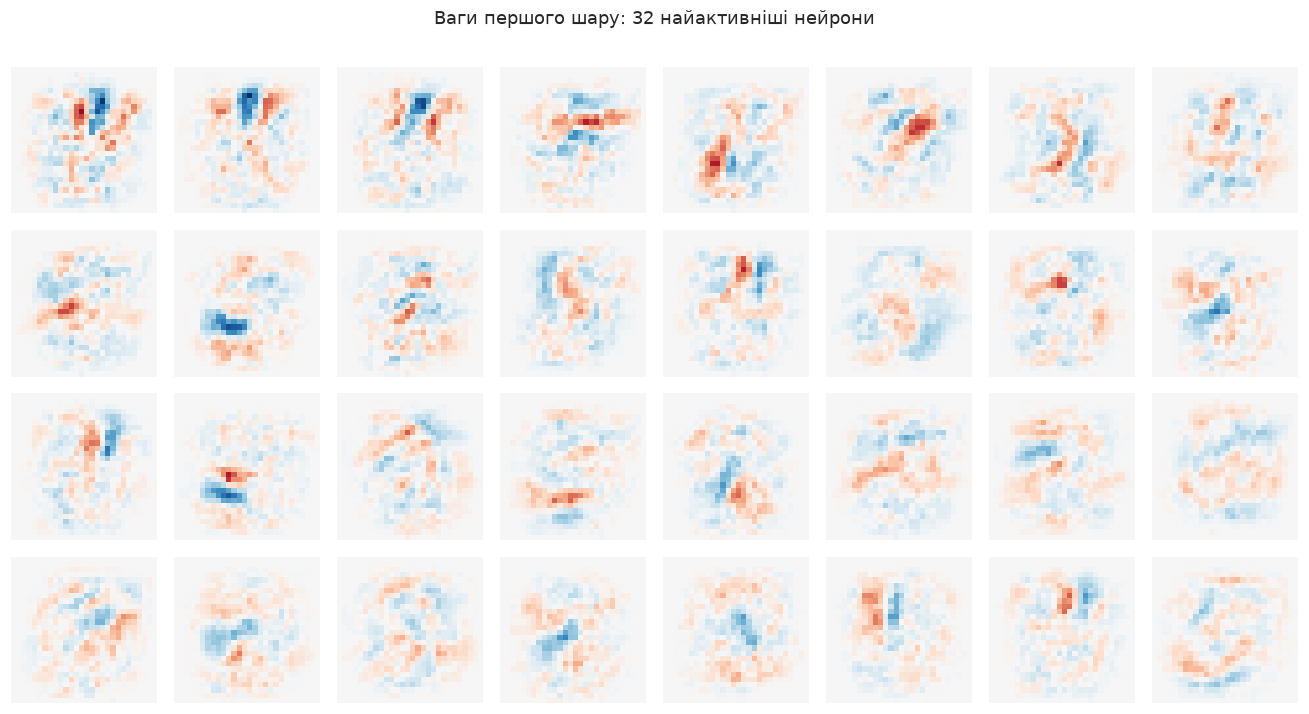

In [12]:
# --- Рисунок 4: ваги першого шару ---
fig, axes = plt.subplots(4, 8, figsize=(12, 6.5))
W = final.coefs_[0]
order = np.argsort(-np.abs(W).sum(axis=0))[:32]
vmax = np.abs(W[:, order]).max()
for ax, i in zip(axes.ravel(), order):
    ax.imshow(W[:, i].reshape(28, 28), cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.axis("off")
plt.suptitle("Ваги першого шару: 32 найактивніші нейрони", y=1.0)
plt.tight_layout()
plt.savefig(ASSETS / "04-weights.png", bbox_inches="tight")
plt.show()

              precision    recall  f1-score   support

           0     0.9876    0.9714    0.9794       245
           1     1.0000    0.9824    0.9911       284
           2     0.9686    0.9574    0.9630       258
           3     0.9760    0.9644    0.9702       253
           4     0.9710    0.9551    0.9630       245
           5     0.9559    0.9731    0.9644       223
           6     0.9424    0.9542    0.9482       240
           7     0.9468    0.9689    0.9577       257
           8     0.9433    0.9588    0.9510       243
           9     0.9567    0.9643    0.9605       252

    accuracy                         0.9652      2500
   macro avg     0.9648    0.9650    0.9649      2500
weighted avg     0.9655    0.9652    0.9653      2500



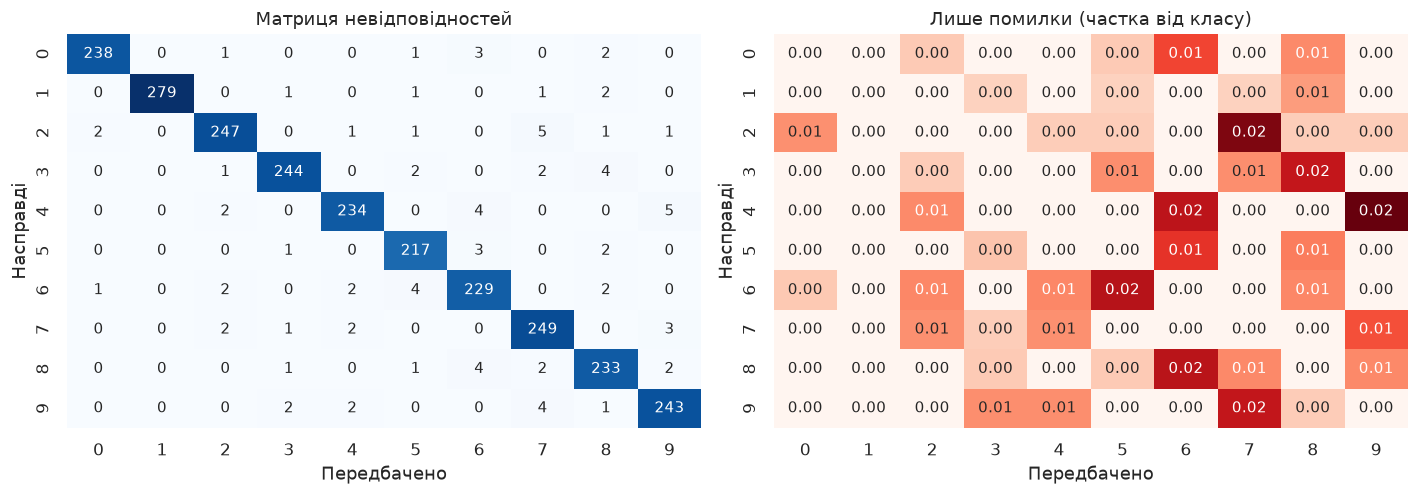

Найчастіші плутанини:
  2 → 7: 5 разів
  4 → 9: 5 разів
  3 → 8: 4 разів
  4 → 6: 4 разів
  6 → 5: 4 разів


In [13]:
pred = final.predict(X_test)
print(classification_report(y_test, pred, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_xlabel("Передбачено"); axes[0].set_ylabel("Насправді")
axes[0].set_title("Матриця невідповідностей")

cm_norm = cm / cm.sum(axis=1, keepdims=True)
np.fill_diagonal(cm_norm, 0)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Reds", cbar=False, ax=axes[1])
axes[1].set_xlabel("Передбачено"); axes[1].set_ylabel("Насправді")
axes[1].set_title("Лише помилки (частка від класу)")
plt.tight_layout()
plt.savefig(ASSETS / "05-confusion.png", bbox_inches="tight")
plt.show()

pairs = [(i, j, cm[i, j]) for i in range(10) for j in range(10) if i != j]
pairs.sort(key=lambda t: -t[2])
print("Найчастіші плутанини:")
for i, j, v in pairs[:5]:
    print(f"  {i} → {j}: {v} разів")

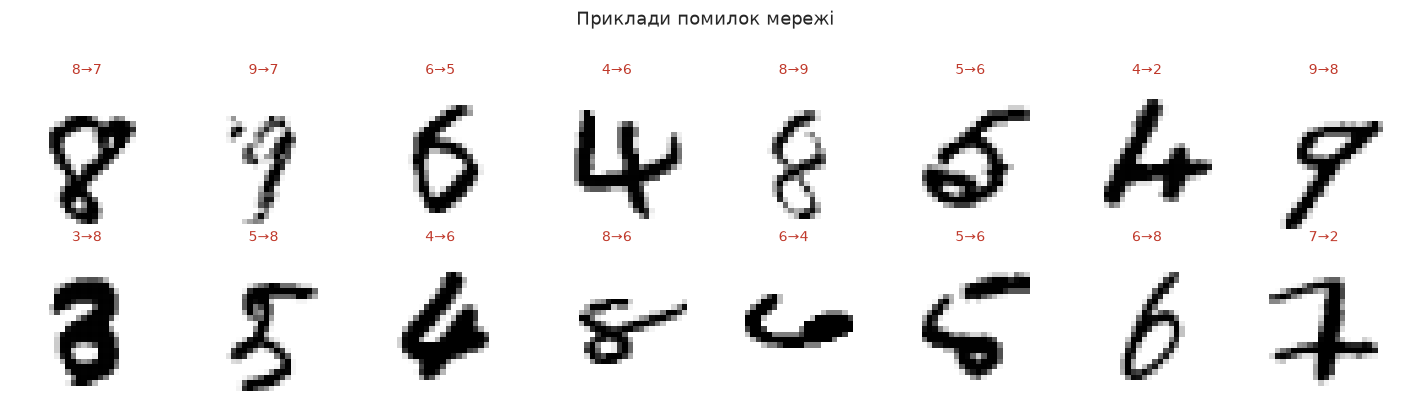

In [14]:
# --- Рисунок 5: приклади помилок ---
wrong = np.where(pred != y_test)[0][:16]
fig, axes = plt.subplots(2, 8, figsize=(13, 3.6))
for ax, i in zip(axes.ravel(), wrong):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray_r")
    ax.set_title(f"{y_test[i]}→{pred[i]}", fontsize=9, color="#c0392b")
    ax.axis("off")
plt.suptitle("Приклади помилок мережі", y=1.03)
plt.tight_layout()
plt.savefig(ASSETS / "06-errors.png", bbox_inches="tight")
plt.show()

## 6. Порівняння з усіма раніше реалізованими алгоритмами

In [15]:
comp_rows = [{"Модель": f"Нейронна мережа ({best_arch[0]} нейронів)",
              "Точність": final.score(X_test, y_test)}]
for name, model in [
    ("SVM RBF (ПЗ № 3)", SVC(kernel="rbf")),
    ("Випадковий ліс (ПЗ № 2)", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
    ("kNN (ПЗ № 5)", KNeighborsClassifier(n_neighbors=5, metric="cosine")),
    ("Логістична регресія (ПЗ № 1)", LogisticRegression(max_iter=1000)),
    ("Наївний Баєс (ПЗ № 4)", MultinomialNB()),
    ("Дерево рішень (ПЗ № 2)", DecisionTreeClassifier(random_state=RANDOM_STATE)),
]:
    model.fit(X_train, y_train)
    comp_rows.append({"Модель": name, "Точність": accuracy_score(y_test, model.predict(X_test))})

comp = pd.DataFrame(comp_rows).set_index("Модель").sort_values("Точність", ascending=False)
comp.to_csv("data/results-summary.csv")
comp.round(4)

,Точність
Модель,
Нейронна мережа (800 нейронів),0.9652
SVM RBF (ПЗ № 3),0.9604
Випадковий ліс (ПЗ № 2),0.9560
kNN (ПЗ № 5),0.9536
Логістична регресія (ПЗ № 1),0.9048
Наївний Баєс (ПЗ № 4),0.8336
Дерево рішень (ПЗ № 2),0.8088


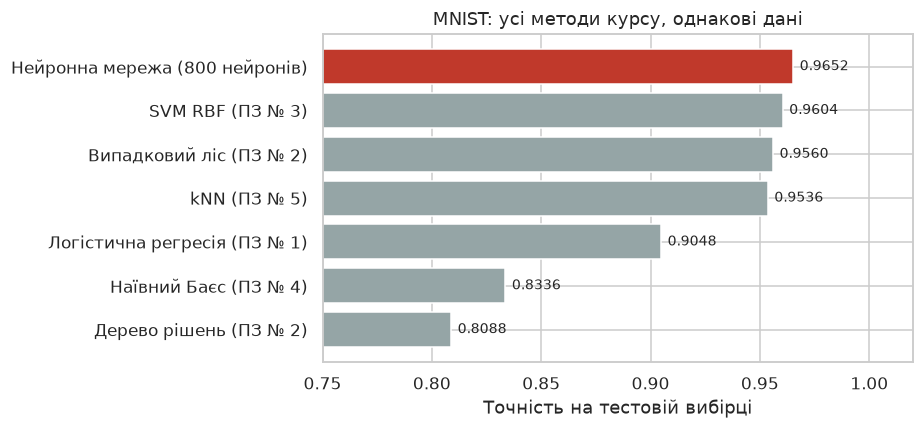

In [16]:
# --- Рисунок 6: підсумкове порівняння ---
fig, ax = plt.subplots(figsize=(8.5, 4))
colors = ["#c0392b" if "Нейронна" in i else "#95a5a6" for i in comp.index]
bars = ax.barh(comp.index[::-1], comp["Точність"][::-1], color=colors[::-1])
ax.set_xlabel("Точність на тестовій вибірці"); ax.set_xlim(0.75, 1.02)
ax.set_title("MNIST: усі методи курсу, однакові дані")
for b, v in zip(bars, comp["Точність"][::-1]):
    ax.text(v + 0.003, b.get_y() + b.get_height()/2, f"{v:.4f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(ASSETS / "07-final.png", bbox_inches="tight")
plt.show()

## 7. Підсумок

In [17]:
print("Архітектура:");    print(arch_df.round(4).to_markdown(index=False)); print()
print("Глибина:");        print(depth_df.round(4).to_markdown()); print()
print("Активація:");      print(act_df.round(4).to_markdown()); print()
print("Регуляризація:");  print(reg_df.round(4).to_markdown(index=False)); print()
print("Усі методи:");     print(comp.round(4).to_markdown())

Архітектура:
|   Нейронів |    Ваг |   Ваг/приклад |   Навчальна |   Тестова |   Розрив |   Час, с |
|-----------:|-------:|--------------:|------------:|----------:|---------:|---------:|
|         10 |   7960 |        1.0613 |      0.9812 |    0.9136 |   0.0676 |   2.8526 |
|         25 |  19885 |        2.6513 |      0.9999 |    0.9324 |   0.0675 |   4.8866 |
|         50 |  39760 |        5.3013 |      1      |    0.944  |   0.056  |  28.119  |
|        100 |  79510 |       10.6013 |      1      |    0.9456 |   0.0544 |  39.7331 |
|        200 | 159010 |       21.2013 |      1      |    0.9536 |   0.0464 |  38.585  |
|        400 | 318010 |       42.4013 |      1      |    0.9556 |   0.0444 |  51.123  |
|        800 | 636010 |       84.8013 |      1      |    0.9596 |   0.0404 |  58.6307 |

Глибина:
| Архітектура                |    Ваг |   Навчальна |   Тестова |   Час, с |
|:---------------------------|-------:|------------:|----------:|---------:|
| 1 шар (100)                | 